In [201]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [202]:
animals = pd.read_csv('animal_data_dirty1.csv', encoding='cp1252')

In [203]:
animals

,Animal type,Country,Weight kg,Body Length,Gender,Animal Code,Latitude,Longitude,Animal Name,Observation Date,Data Complied By
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.01.2024,James Johnson
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.02.2024,James Johnson
2,European bison,Poland,930.000,335.0,male,NaN,52.828845,23.820144,Szefu,01.03.2024,Anne Anthony
3,European bison,Poland,909.000,311.0,not determined,NaN,52.830509,23.826849,NaN,01.03.2024,Anne Anthony
4,European bison™,Poland,581.000,277.0,female,NaN,52.834109,23.807093,NaN,01.03.2024,Anne Anthony
...,...,...,...,...,...,...,...,...,...,...,...
1006,red squirrel,Poland,0.346,20.0,female,NaN,52.212001,21.033187,Lola,7-May-24,Anne Anthony
1007,hedgehog,Germany,1.000,23.0,female,NaN,49.561356,11.105334,NaN,7-May-24,Bob Bobson
1008,hedgehog,Germany,0.500,17.0,female,NaN,49.561569,11.087046,NaN,7-May-24,Bob Bobson
1009,red squirrel,Poland,0.346,20.0,female,NaN,52.212001,21.033187,Lola,7-May-24,Anne Anthony


In [204]:
animals.dtypes

Animal type          object
Country              object
Weight kg           float64
Body Length         float64
Gender               object
Animal Code         float64
Latitude            float64
Longitude           float64
Animal Name          object
Observation Date     object
Data Complied By     object
dtype: object

In [205]:
#data cleaning steps 

In [206]:
#Step 1: Remove Animal Code 

In [207]:
animals = animals.drop('Animal Code', axis=1)

In [208]:
animals

,Animal type,Country,Weight kg,Body Length,Gender,Latitude,Longitude,Animal Name,Observation Date,Data Complied By
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.01.2024,James Johnson
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,03.02.2024,James Johnson
2,European bison,Poland,930.000,335.0,male,52.828845,23.820144,Szefu,01.03.2024,Anne Anthony
3,European bison,Poland,909.000,311.0,not determined,52.830509,23.826849,NaN,01.03.2024,Anne Anthony
4,European bison™,Poland,581.000,277.0,female,52.834109,23.807093,NaN,01.03.2024,Anne Anthony
...,...,...,...,...,...,...,...,...,...,...
1006,red squirrel,Poland,0.346,20.0,female,52.212001,21.033187,Lola,7-May-24,Anne Anthony
1007,hedgehog,Germany,1.000,23.0,female,49.561356,11.105334,NaN,7-May-24,Bob Bobson
1008,hedgehog,Germany,0.500,17.0,female,49.561569,11.087046,NaN,7-May-24,Bob Bobson
1009,red squirrel,Poland,0.346,20.0,female,52.212001,21.033187,Lola,7-May-24,Anne Anthony


In [209]:
#Convert Null Vlaues to not Determined

In [210]:
animals['Gender'].value_counts()

Gender
male              499
female            488
not determined      5
Name: count, dtype: int64

In [211]:
animals['Gender'].fillna('not determined', inplace=True)

C:\Users\alexh\AppData\Local\Temp\ipykernel_21180\3488840020.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  animals['Gender'].fillna('not determined', inplace=True)


In [212]:
animals['Gender'].value_counts()

Gender
male              499
female            488
not determined     24
Name: count, dtype: int64

In [213]:
#Step 3: drop animal name 

In [214]:
animals = animals.drop('Animal Name', axis=1)

In [215]:
# Step 4 convert observation date to data type of B d Y 

In [216]:
animals["Observation Date"] = pd.to_datetime(
    animals["Observation Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

In [217]:
animals

,Animal type,Country,Weight kg,Body Length,Gender,Latitude,Longitude,Observation Date,Data Complied By
0,NaN,NaN,NaN,NaN,not determined,NaN,NaN,2024-01-03,James Johnson
1,NaN,NaN,NaN,NaN,not determined,NaN,NaN,2024-02-03,James Johnson
2,European bison,Poland,930.000,335.0,male,52.828845,23.820144,2024-03-01,Anne Anthony
3,European bison,Poland,909.000,311.0,not determined,52.830509,23.826849,2024-03-01,Anne Anthony
4,European bison™,Poland,581.000,277.0,female,52.834109,23.807093,2024-03-01,Anne Anthony
...,...,...,...,...,...,...,...,...,...
1006,red squirrel,Poland,0.346,20.0,female,52.212001,21.033187,2024-05-07,Anne Anthony
1007,hedgehog,Germany,1.000,23.0,female,49.561356,11.105334,2024-05-07,Bob Bobson
1008,hedgehog,Germany,0.500,17.0,female,49.561569,11.087046,2024-05-07,Bob Bobson
1009,red squirrel,Poland,0.346,20.0,female,52.212001,21.033187,2024-05-07,Anne Anthony


In [218]:
animals["Observation Date"].sample(15)

603   2024-04-06
632   2024-04-06
736   2024-04-15
809   2024-04-25
289   2024-03-14
735   2024-04-15
255   2024-03-11
561   2024-04-03
751   2024-04-17
16    2024-03-01
454   2024-03-26
99    2024-03-02
346   2024-03-19
301   2024-03-14
889   2024-05-22
Name: Observation Date, dtype: datetime64[ns]

In [219]:
animals

,Animal type,Country,Weight kg,Body Length,Gender,Latitude,Longitude,Observation Date,Data Complied By
0,NaN,NaN,NaN,NaN,not determined,NaN,NaN,2024-01-03,James Johnson
1,NaN,NaN,NaN,NaN,not determined,NaN,NaN,2024-02-03,James Johnson
2,European bison,Poland,930.000,335.0,male,52.828845,23.820144,2024-03-01,Anne Anthony
3,European bison,Poland,909.000,311.0,not determined,52.830509,23.826849,2024-03-01,Anne Anthony
4,European bison™,Poland,581.000,277.0,female,52.834109,23.807093,2024-03-01,Anne Anthony
...,...,...,...,...,...,...,...,...,...
1006,red squirrel,Poland,0.346,20.0,female,52.212001,21.033187,2024-05-07,Anne Anthony
1007,hedgehog,Germany,1.000,23.0,female,49.561356,11.105334,2024-05-07,Bob Bobson
1008,hedgehog,Germany,0.500,17.0,female,49.561569,11.087046,2024-05-07,Bob Bobson
1009,red squirrel,Poland,0.346,20.0,female,52.212001,21.033187,2024-05-07,Anne Anthony


In [220]:
#Step 5: fill in blank country values with unknown

In [221]:
animals["Country"].fillna("Unknown", inplace=True)

C:\Users\alexh\AppData\Local\Temp\ipykernel_21180\1924335270.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  animals["Country"].fillna("Unknown", inplace=True)


In [222]:
#Step 6
#rename body length column
#fill in null value with the mean body length 
#set the body length to 

In [223]:
animals = animals.rename(columns={"Body Length": "Body Length (CM)"})

In [224]:
animals

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By
0,NaN,Unknown,NaN,NaN,not determined,NaN,NaN,2024-01-03,James Johnson
1,NaN,Unknown,NaN,NaN,not determined,NaN,NaN,2024-02-03,James Johnson
2,European bison,Poland,930.000,335.0,male,52.828845,23.820144,2024-03-01,Anne Anthony
3,European bison,Poland,909.000,311.0,not determined,52.830509,23.826849,2024-03-01,Anne Anthony
4,European bison™,Poland,581.000,277.0,female,52.834109,23.807093,2024-03-01,Anne Anthony
...,...,...,...,...,...,...,...,...,...
1006,red squirrel,Poland,0.346,20.0,female,52.212001,21.033187,2024-05-07,Anne Anthony
1007,hedgehog,Germany,1.000,23.0,female,49.561356,11.105334,2024-05-07,Bob Bobson
1008,hedgehog,Germany,0.500,17.0,female,49.561569,11.087046,2024-05-07,Bob Bobson
1009,red squirrel,Poland,0.346,20.0,female,52.212001,21.033187,2024-05-07,Anne Anthony


In [225]:
animals["Body Length (CM)"].fillna(animals["Body Length (CM)"].mean(), inplace=True)

C:\Users\alexh\AppData\Local\Temp\ipykernel_21180\4034454013.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  animals["Body Length (CM)"].fillna(animals["Body Length (CM)"].mean(), inplace=True)


In [226]:
animals["Body Length (CM)"] = animals["Body Length (CM)"].round(2)

In [227]:
animals

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By
0,NaN,Unknown,NaN,39.11,not determined,NaN,NaN,2024-01-03,James Johnson
1,NaN,Unknown,NaN,39.11,not determined,NaN,NaN,2024-02-03,James Johnson
2,European bison,Poland,930.000,335.00,male,52.828845,23.820144,2024-03-01,Anne Anthony
3,European bison,Poland,909.000,311.00,not determined,52.830509,23.826849,2024-03-01,Anne Anthony
4,European bison™,Poland,581.000,277.00,female,52.834109,23.807093,2024-03-01,Anne Anthony
...,...,...,...,...,...,...,...,...,...
1006,red squirrel,Poland,0.346,20.00,female,52.212001,21.033187,2024-05-07,Anne Anthony
1007,hedgehog,Germany,1.000,23.00,female,49.561356,11.105334,2024-05-07,Bob Bobson
1008,hedgehog,Germany,0.500,17.00,female,49.561569,11.087046,2024-05-07,Bob Bobson
1009,red squirrel,Poland,0.346,20.00,female,52.212001,21.033187,2024-05-07,Anne Anthony


In [228]:
#Step 7
#convert null kg to mean kg
#convert weight kg to weight lbs
#convert weight kg to round to 2 

In [229]:
animals["Weight kg"].mean()

39.745503048780485

In [230]:
animals["Weight kg"] = animals["Weight kg"].astype(np.float64)

In [231]:
animals["Weight kg"].fillna(animals["Weight kg"].mean(), inplace=True)

C:\Users\alexh\AppData\Local\Temp\ipykernel_21180\422589594.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  animals["Weight kg"].fillna(animals["Weight kg"].mean(), inplace=True)


In [232]:
animals

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By
0,NaN,Unknown,39.745503,39.11,not determined,NaN,NaN,2024-01-03,James Johnson
1,NaN,Unknown,39.745503,39.11,not determined,NaN,NaN,2024-02-03,James Johnson
2,European bison,Poland,930.000000,335.00,male,52.828845,23.820144,2024-03-01,Anne Anthony
3,European bison,Poland,909.000000,311.00,not determined,52.830509,23.826849,2024-03-01,Anne Anthony
4,European bison™,Poland,581.000000,277.00,female,52.834109,23.807093,2024-03-01,Anne Anthony
...,...,...,...,...,...,...,...,...,...
1006,red squirrel,Poland,0.346000,20.00,female,52.212001,21.033187,2024-05-07,Anne Anthony
1007,hedgehog,Germany,1.000000,23.00,female,49.561356,11.105334,2024-05-07,Bob Bobson
1008,hedgehog,Germany,0.500000,17.00,female,49.561569,11.087046,2024-05-07,Bob Bobson
1009,red squirrel,Poland,0.346000,20.00,female,52.212001,21.033187,2024-05-07,Anne Anthony


In [233]:
animals["Weight kg"] = animals["Weight kg"].round(2)

In [234]:
animals

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By
0,NaN,Unknown,39.75,39.11,not determined,NaN,NaN,2024-01-03,James Johnson
1,NaN,Unknown,39.75,39.11,not determined,NaN,NaN,2024-02-03,James Johnson
2,European bison,Poland,930.00,335.00,male,52.828845,23.820144,2024-03-01,Anne Anthony
3,European bison,Poland,909.00,311.00,not determined,52.830509,23.826849,2024-03-01,Anne Anthony
4,European bison™,Poland,581.00,277.00,female,52.834109,23.807093,2024-03-01,Anne Anthony
...,...,...,...,...,...,...,...,...,...
1006,red squirrel,Poland,0.35,20.00,female,52.212001,21.033187,2024-05-07,Anne Anthony
1007,hedgehog,Germany,1.00,23.00,female,49.561356,11.105334,2024-05-07,Bob Bobson
1008,hedgehog,Germany,0.50,17.00,female,49.561569,11.087046,2024-05-07,Bob Bobson
1009,red squirrel,Poland,0.35,20.00,female,52.212001,21.033187,2024-05-07,Anne Anthony


In [235]:
animals["Weight lbs"] = animals["Weight kg"] * 2.20462

In [236]:
animals["Weight lbs"] = animals["Weight lbs"].round(2)

In [237]:
animals

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs
0,NaN,Unknown,39.75,39.11,not determined,NaN,NaN,2024-01-03,James Johnson,87.63
1,NaN,Unknown,39.75,39.11,not determined,NaN,NaN,2024-02-03,James Johnson,87.63
2,European bison,Poland,930.00,335.00,male,52.828845,23.820144,2024-03-01,Anne Anthony,2050.30
3,European bison,Poland,909.00,311.00,not determined,52.830509,23.826849,2024-03-01,Anne Anthony,2004.00
4,European bison™,Poland,581.00,277.00,female,52.834109,23.807093,2024-03-01,Anne Anthony,1280.88
...,...,...,...,...,...,...,...,...,...,...
1006,red squirrel,Poland,0.35,20.00,female,52.212001,21.033187,2024-05-07,Anne Anthony,0.77
1007,hedgehog,Germany,1.00,23.00,female,49.561356,11.105334,2024-05-07,Bob Bobson,2.20
1008,hedgehog,Germany,0.50,17.00,female,49.561569,11.087046,2024-05-07,Bob Bobson,1.10
1009,red squirrel,Poland,0.35,20.00,female,52.212001,21.033187,2024-05-07,Anne Anthony,0.77


In [238]:
#Step 8: Fill in Unknown

In [239]:
animals["Animal type"].fillna("Unknown", inplace=True)

C:\Users\alexh\AppData\Local\Temp\ipykernel_21180\3049134322.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  animals["Animal type"].fillna("Unknown", inplace=True)


In [240]:
animals["Animal type"].value_counts()

Animal type
red squirrel       543
hedgehog           274
lynx                61
European bison      49
red squirrell       22
Unknown             20
red squirel         14
lynx?               10
European bison™      6
European bisson      4
European buster      4
ledgehod             3
wedgehod             1
Name: count, dtype: int64

In [241]:
animals['Animal type'] = animals['Animal type'].replace({'European bison™': 'European bison', 
                                                         'European bisson': 'European bison',
                                                         "European buster": 'European bison',
                                                        'lynx?': 'lynx',
                                                        'red squirrell': 'red squirrel',
                                                         'red squirel': 'red squirrel',
                                                        'ledgehod': 'hedgehog',
                                                        'wedgehod': 'hedgehog'})

In [242]:
animals["Animal type"].value_counts()

Animal type
red squirrel      579
hedgehog          278
lynx               71
European bison     63
Unknown            20
Name: count, dtype: int64

In [243]:
#Step 9: Lattiude and Longitude 

In [244]:
animals["Latitude"].fillna(0, inplace=True)

C:\Users\alexh\AppData\Local\Temp\ipykernel_21180\1752233646.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  animals["Latitude"].fillna(0, inplace=True)


In [245]:
animals["Longitude"].fillna(0, inplace=True)

C:\Users\alexh\AppData\Local\Temp\ipykernel_21180\1622421643.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  animals["Longitude"].fillna(0, inplace=True)


In [246]:
animals["Longitude"] = animals["Longitude"].round(4)

In [247]:
animals["Latitude"] = animals["Latitude"].round(4)

In [248]:
animals

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs
0,Unknown,Unknown,39.75,39.11,not determined,0.0000,0.0000,2024-01-03,James Johnson,87.63
1,Unknown,Unknown,39.75,39.11,not determined,0.0000,0.0000,2024-02-03,James Johnson,87.63
2,European bison,Poland,930.00,335.00,male,52.8288,23.8201,2024-03-01,Anne Anthony,2050.30
3,European bison,Poland,909.00,311.00,not determined,52.8305,23.8268,2024-03-01,Anne Anthony,2004.00
4,European bison,Poland,581.00,277.00,female,52.8341,23.8071,2024-03-01,Anne Anthony,1280.88
...,...,...,...,...,...,...,...,...,...,...
1006,red squirrel,Poland,0.35,20.00,female,52.2120,21.0332,2024-05-07,Anne Anthony,0.77
1007,hedgehog,Germany,1.00,23.00,female,49.5614,11.1053,2024-05-07,Bob Bobson,2.20
1008,hedgehog,Germany,0.50,17.00,female,49.5616,11.0870,2024-05-07,Bob Bobson,1.10
1009,red squirrel,Poland,0.35,20.00,female,52.2120,21.0332,2024-05-07,Anne Anthony,0.77


In [249]:
animals["Country"].value_counts()

Country
Poland            291
Germany           176
Slovakia          151
Hungary           146
Czech Republic    103
Austria            74
PL                 15
Unknown            12
HU                 11
Hungry             10
CZ                  5
DE                  5
Czech               4
Australia           4
CC                  4
Name: count, dtype: int64

In [250]:
animals["Country"] = animals["Country"].replace({"PL": 'Poland',
                                               "HU": "Hungry",
                                               "CZ": "Czech Republic",
                                               "Czech": "Czech Republic",
                                               "DE": "Germany",
                                               "CC": "Cocos (Keeling) Islands"})

**Check for Duplicates and Remove if necessary**

In [251]:
duplication = animals[animals.duplicated()]

In [252]:
duplication

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs
31,red squirrel,Germany,0.26,21.0,male,0.0000,0.0000,2024-03-01,Bob Bobson,0.57
33,red squirrel,Germany,0.29,19.0,male,0.0000,0.0000,2024-03-01,Bob Bobson,0.64
51,red squirrel,Poland,0.31,22.0,female,52.2413,21.0557,2024-03-01,Anne Anthony,0.68
52,red squirrel,Poland,0.35,20.0,female,52.2421,21.0578,2024-03-01,Anne Anthony,0.77
53,red squirrel,Poland,0.32,20.0,male,52.2400,21.0562,2024-03-01,Anne Anthony,0.71
...,...,...,...,...,...,...,...,...,...,...
988,red squirrel,Poland,0.32,19.0,female,52.2123,21.0336,2024-05-04,Anne Anthony,0.71
1002,red squirrel,Poland,0.30,22.0,male,52.2128,21.0342,2024-05-06,Anne Anthony,0.66
1003,red squirrel,Poland,0.34,22.0,male,52.2125,21.0335,2024-05-06,Anne Anthony,0.75
1004,red squirrel,Poland,0.31,20.0,female,52.2121,21.0335,2024-05-06,Anne Anthony,0.68


In [253]:
animals = animals.drop_duplicates()

In [254]:
animals

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs
0,Unknown,Unknown,39.75,39.11,not determined,0.0000,0.0000,2024-01-03,James Johnson,87.63
1,Unknown,Unknown,39.75,39.11,not determined,0.0000,0.0000,2024-02-03,James Johnson,87.63
2,European bison,Poland,930.00,335.00,male,52.8288,23.8201,2024-03-01,Anne Anthony,2050.30
3,European bison,Poland,909.00,311.00,not determined,52.8305,23.8268,2024-03-01,Anne Anthony,2004.00
4,European bison,Poland,581.00,277.00,female,52.8341,23.8071,2024-03-01,Anne Anthony,1280.88
...,...,...,...,...,...,...,...,...,...,...
1005,hedgehog,Hungary,0.90,23.00,male,47.5101,18.9444,2024-05-07,Anne Anthony,1.98
1006,red squirrel,Poland,0.35,20.00,female,52.2120,21.0332,2024-05-07,Anne Anthony,0.77
1007,hedgehog,Germany,1.00,23.00,female,49.5614,11.1053,2024-05-07,Bob Bobson,2.20
1008,hedgehog,Germany,0.50,17.00,female,49.5616,11.0870,2024-05-07,Bob Bobson,1.10


In [255]:
dummies = pd.get_dummies(animals['Gender'], prefix='Gender')

In [256]:
animals = pd.concat([animals, dummies], axis=1)

In [257]:
animals

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs,Gender_female,Gender_male,Gender_not determined
0,Unknown,Unknown,39.75,39.11,not determined,0.0000,0.0000,2024-01-03,James Johnson,87.63,False,False,True
1,Unknown,Unknown,39.75,39.11,not determined,0.0000,0.0000,2024-02-03,James Johnson,87.63,False,False,True
2,European bison,Poland,930.00,335.00,male,52.8288,23.8201,2024-03-01,Anne Anthony,2050.30,False,True,False
3,European bison,Poland,909.00,311.00,not determined,52.8305,23.8268,2024-03-01,Anne Anthony,2004.00,False,False,True
4,European bison,Poland,581.00,277.00,female,52.8341,23.8071,2024-03-01,Anne Anthony,1280.88,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1005,hedgehog,Hungary,0.90,23.00,male,47.5101,18.9444,2024-05-07,Anne Anthony,1.98,False,True,False
1006,red squirrel,Poland,0.35,20.00,female,52.2120,21.0332,2024-05-07,Anne Anthony,0.77,True,False,False
1007,hedgehog,Germany,1.00,23.00,female,49.5614,11.1053,2024-05-07,Bob Bobson,2.20,True,False,False
1008,hedgehog,Germany,0.50,17.00,female,49.5616,11.0870,2024-05-07,Bob Bobson,1.10,True,False,False


**Data Exploration**

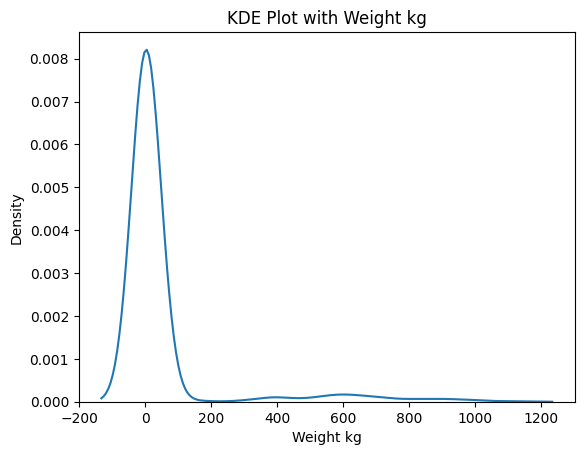

In [258]:
plt.title("KDE Plot with Weight kg")
sns.kdeplot(data=animals, x="Weight kg")
plt.xlabel("Weight kg")
plt.show()

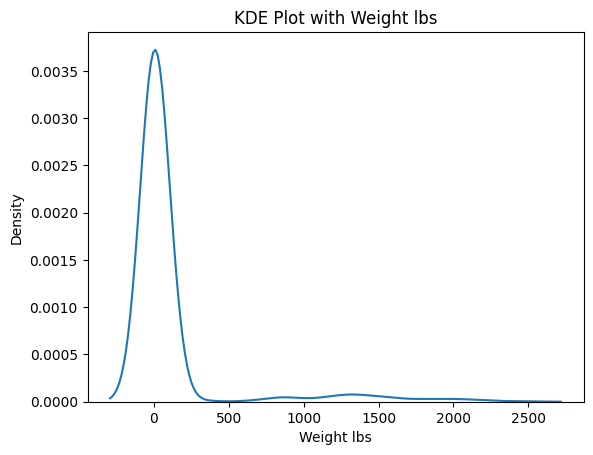

In [259]:
plt.title("KDE Plot with Weight lbs")
sns.kdeplot(data=animals, x="Weight lbs")
plt.xlabel("Weight lbs")
plt.show()

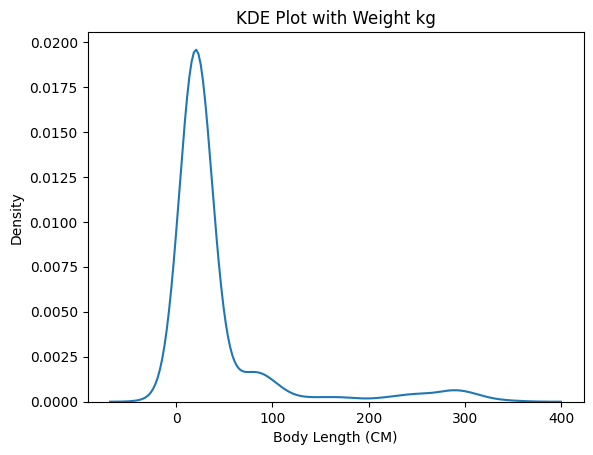

In [260]:
plt.title("KDE Plot with Weight kg")
sns.kdeplot(data=animals, x="Body Length (CM)")
plt.xlabel("Body Length (CM)")
plt.show()

In [261]:
order2 = animals["Animal type"].value_counts().index

In [262]:
order2

Index(['red squirrel', 'hedgehog', 'lynx', 'European bison', 'Unknown'], dtype='object', name='Animal type')

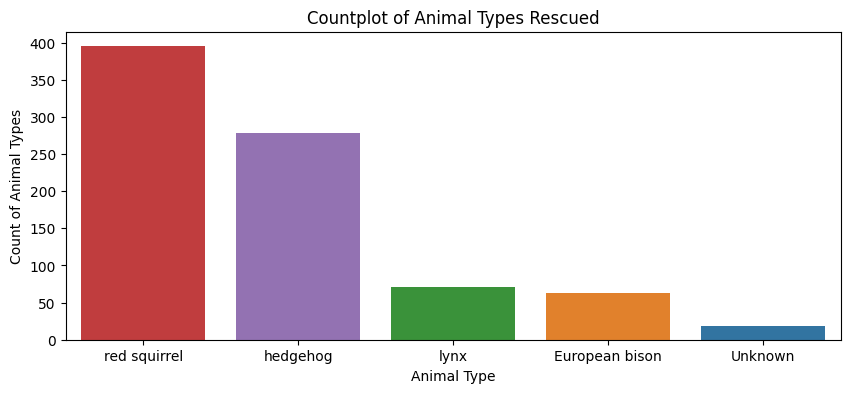

In [263]:
plt.figure(figsize=(10, 4))
plt.title("Countplot of Animal Types Rescued")
sns.countplot(data=animals, x="Animal type", order=order2, hue="Animal type")
plt.xlabel("Animal Type")
plt.ylabel("Count of Animal Types")
plt.show()

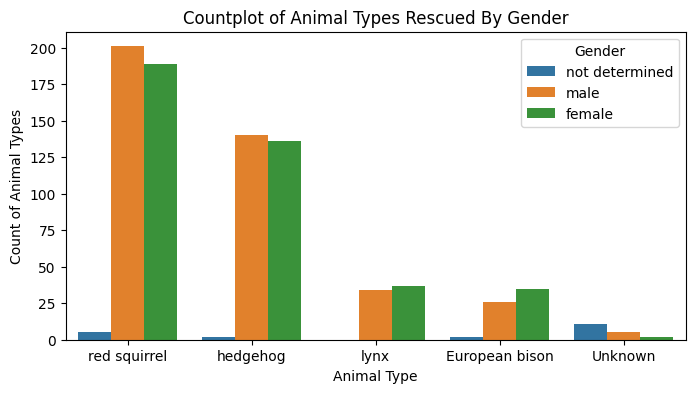

In [264]:
plt.figure(figsize=(8, 4))
plt.title("Countplot of Animal Types Rescued By Gender")
sns.countplot(data=animals, x="Animal type", order=order2, hue="Gender")
plt.xlabel("Animal Type")
plt.ylabel("Count of Animal Types")
plt.show()

In [265]:
order3 = animals["Country"].value_counts().index

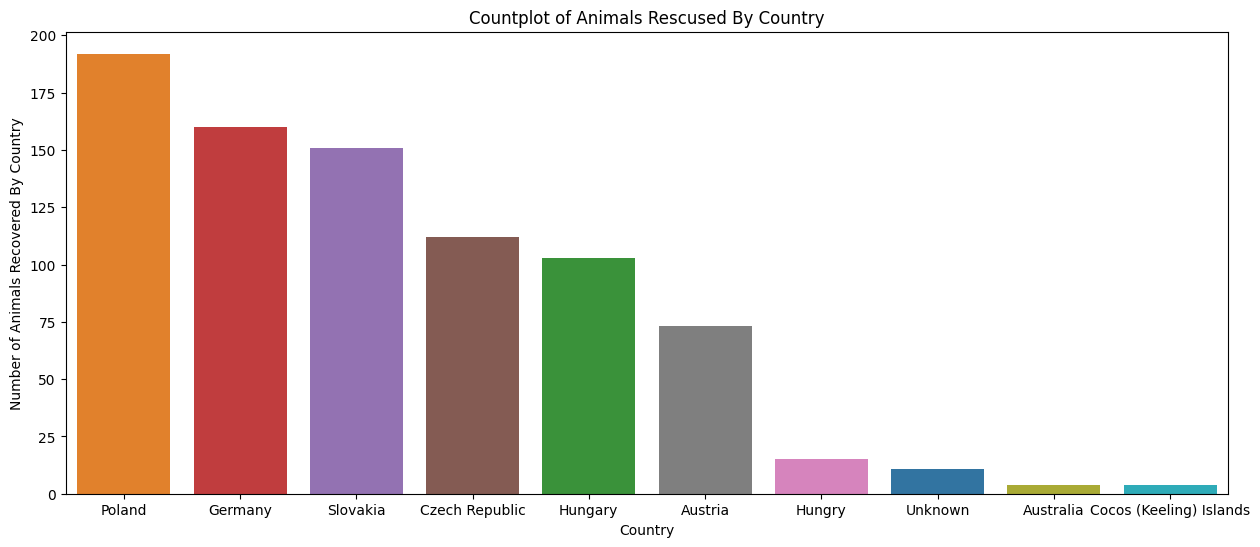

In [266]:
plt.figure(figsize=(15, 6))
plt.title("Countplot of Animals Rescused By Country")
sns.countplot(data=animals, x="Country", order=order3, hue="Country")
plt.xlabel("Country")
plt.ylabel("Number of Animals Recovered By Country")
plt.show()

In [267]:
order4 = animals["Data Complied By"].value_counts().index

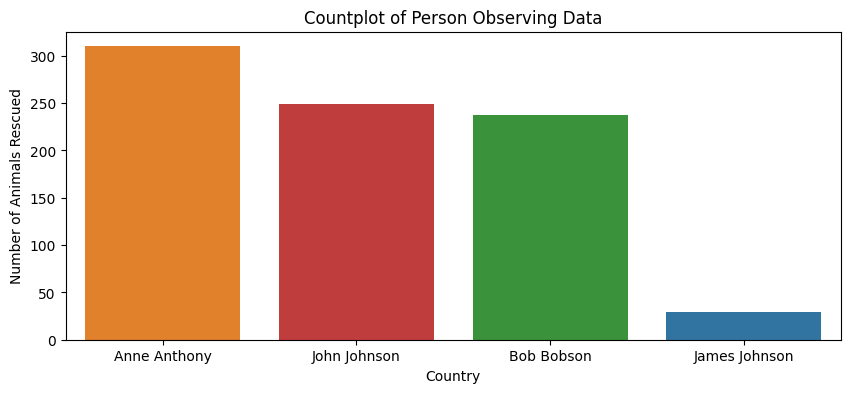

In [268]:
plt.figure(figsize=(10, 4))
plt.title("Countplot of Person Observing Data")
sns.countplot(data=animals, x="Data Complied By", order=order4, hue="Data Complied By")
plt.xlabel("Country")
plt.ylabel("Number of Animals Rescued")
plt.show()

In [269]:
order5 = animals["Gender"].value_counts().index

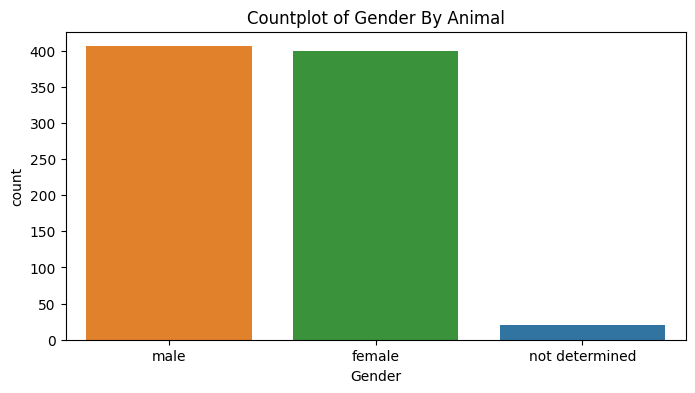

In [270]:
plt.figure(figsize=(8, 4))
plt.title("Countplot of Gender By Animal")
sns.countplot(data=animals, x="Gender", hue="Gender", order=order5)
plt.show()

In [271]:
EuopeanBison = animals[animals["Animal type"] == "European bison"]

In [272]:
medians1 = EuopeanBison.groupby('Country')['Weight lbs'].median()
ordered_categories1 = medians1.sort_values(ascending=False).index

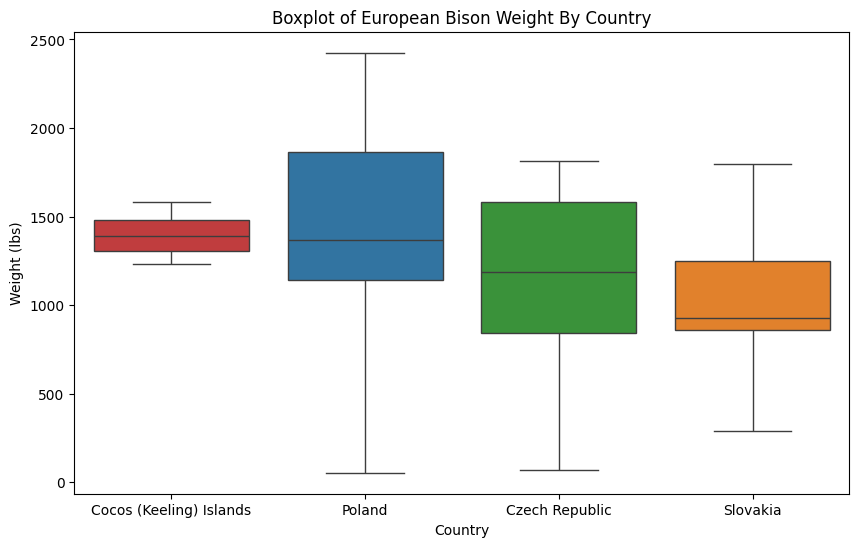

In [273]:
plt.figure(figsize=(10, 6))
plt.title("Boxplot of European Bison Weight By Country")
Boxplot = sns.boxplot(data=EuopeanBison, x="Country", y="Weight lbs", order=ordered_categories1, hue="Country")
plt.xlabel("Country")
plt.ylabel("Weight (lbs)")
plt.show()

In [274]:
lynx = animals[animals["Animal type"] == "lynx"]

In [275]:
lynx["Country"].value_counts().sort_values(ascending=False)

Country
Slovakia          26
Poland            19
Hungary           10
Czech Republic     8
Austria            5
Hungry             3
Name: count, dtype: int64

In [276]:
medians = lynx.groupby('Country')['Weight lbs'].median()
ordered_categories = medians.sort_values(ascending=False).index

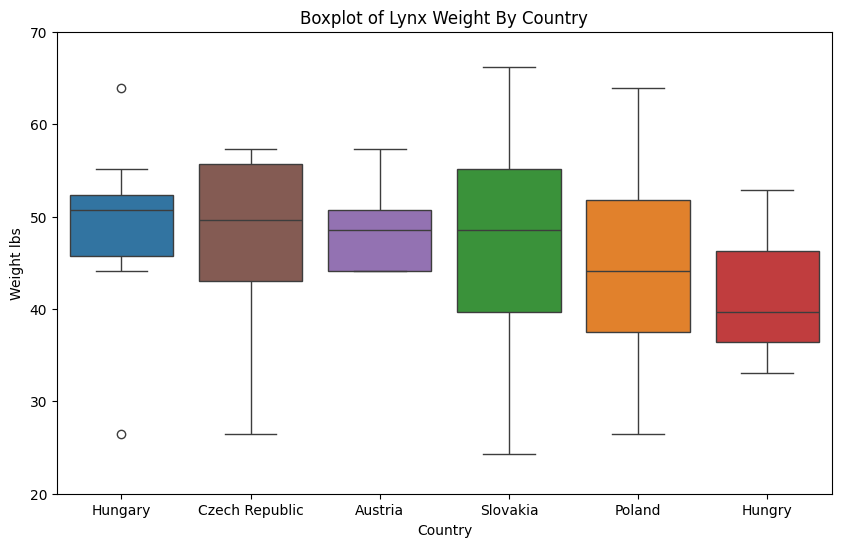

In [277]:
plt.figure(figsize=(10, 6))
plt.title("Boxplot of Lynx Weight By Country")
sns.boxplot(data=lynx, x="Country", y="Weight lbs", hue="Country", order=ordered_categories)
plt.xlabel("Country")
plt.ylabel("Weight lbs")
plt.ylim(20, 70)
plt.show()

In [278]:
hedgehog = animals[animals["Animal type"] == "hedgehog"]

In [279]:
medians2 = hedgehog.groupby("Country")["Weight lbs"].median()
ordered_categories2 = medians2.sort_values(ascending=False).index

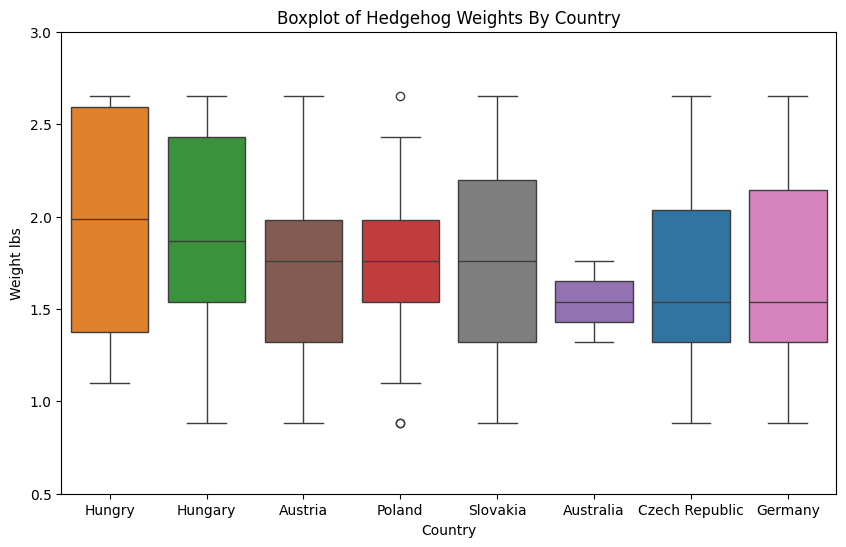

In [280]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=hedgehog, x="Country", y="Weight lbs", hue="Country", order=ordered_categories2)
plt.title("Boxplot of Hedgehog Weights By Country")
plt.ylim(0.5, 3.0)
plt.xlabel("Country")
plt.show()

In [281]:
RedSquirrel = animals[animals["Animal type"] == "red squirrel"]

In [282]:
medians3 = RedSquirrel.groupby("Country")["Weight lbs"].median()
ordered_categories3 = medians3.sort_values(ascending=False).index

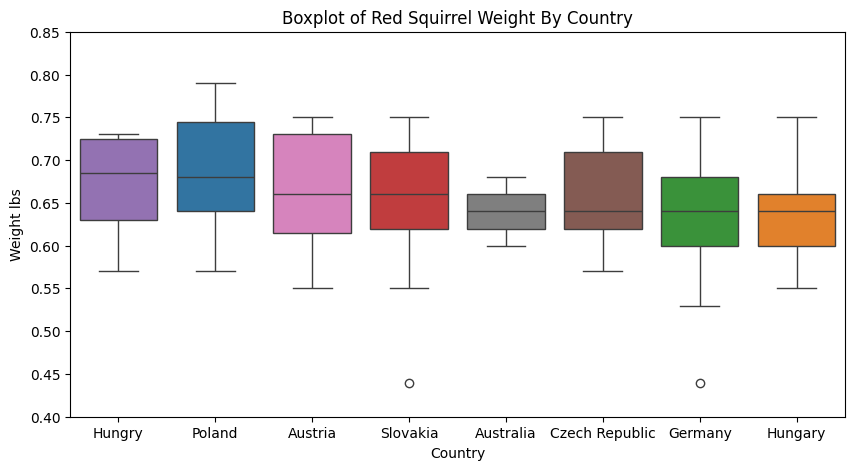

In [283]:
plt.figure(figsize=(10, 5))
plt.title("Boxplot of Red Squirrel Weight By Country")
sns.boxplot(data=RedSquirrel, x="Country", y="Weight lbs", hue="Country", order=ordered_categories3)
plt.ylim(0.4, 0.85)
plt.show()

In [284]:
numerics = animals[['Weight lbs', 'Body Length (CM)', "Weight kg"]]

In [285]:
matrix = numerics.corr()

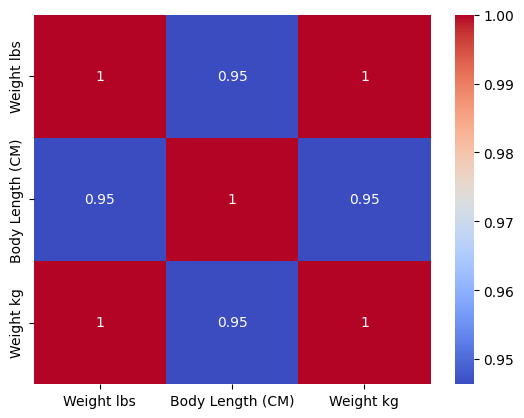

In [286]:
sns.heatmap(matrix, annot=True, cmap='coolwarm')
plt.show()

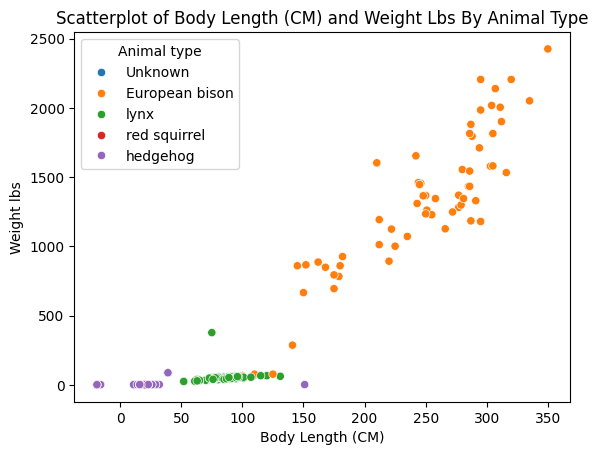

In [287]:
plt.title("Scatterplot of Body Length (CM) and Weight Lbs By Animal Type")
sns.scatterplot(data=animals, x="Body Length (CM)", y="Weight lbs", hue="Animal type")
plt.xlabel("Body Length (CM)")
plt.ylabel("Weight lbs")
plt.show()

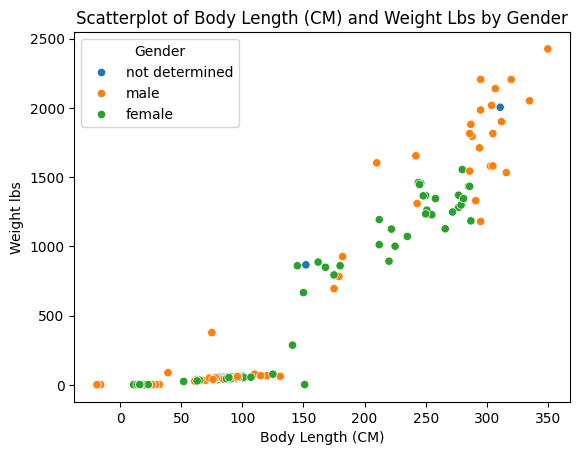

In [288]:
plt.title("Scatterplot of Body Length (CM) and Weight Lbs by Gender")
sns.scatterplot(data=animals, x="Body Length (CM)", y="Weight lbs", hue="Gender")
plt.show()

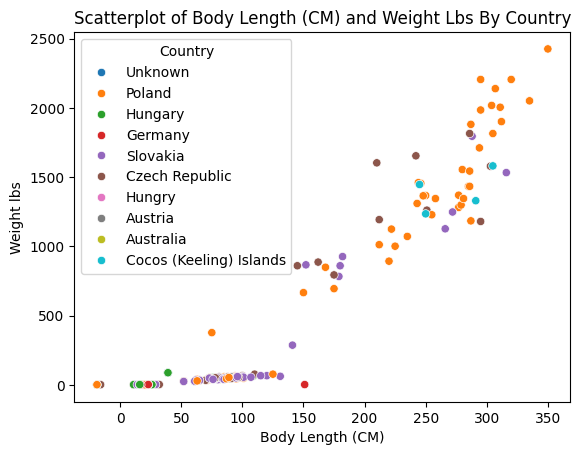

In [289]:
plt.title("Scatterplot of Body Length (CM) and Weight Lbs By Country")
sns.scatterplot(data=animals, x="Body Length (CM)", y="Weight lbs", hue="Country")
plt.show()

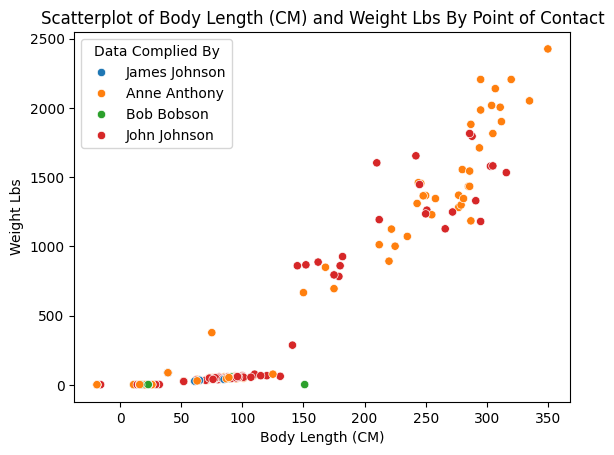

In [290]:
plt.title("Scatterplot of Body Length (CM) and Weight Lbs By Point of Contact")
sns.scatterplot(data=animals, x="Body Length (CM)", y="Weight lbs", hue="Data Complied By")
plt.xlabel("Body Length (CM)")
plt.ylabel("Weight Lbs")
plt.show()

In [291]:
DataPoints = animals[animals["Latitude"] > 0 & (animals["Longitude"] > 0)]

In [292]:
DataPoints

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs,Gender_female,Gender_male,Gender_not determined
2,European bison,Poland,930.00,335.0,male,52.8288,23.8201,2024-03-01,Anne Anthony,2050.30,False,True,False
3,European bison,Poland,909.00,311.0,not determined,52.8305,23.8268,2024-03-01,Anne Anthony,2004.00,False,False,True
4,European bison,Poland,581.00,277.0,female,52.8341,23.8071,2024-03-01,Anne Anthony,1280.88,True,False,False
5,European bison,Poland,900.00,295.0,male,52.8348,23.8172,2024-03-01,Anne Anthony,1984.16,False,True,False
6,European bison,Poland,620.00,250.0,female,52.8350,23.8208,2024-03-01,Anne Anthony,1366.86,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1005,hedgehog,Hungary,0.90,23.0,male,47.5101,18.9444,2024-05-07,Anne Anthony,1.98,False,True,False
1006,red squirrel,Poland,0.35,20.0,female,52.2120,21.0332,2024-05-07,Anne Anthony,0.77,True,False,False
1007,hedgehog,Germany,1.00,23.0,female,49.5614,11.1053,2024-05-07,Bob Bobson,2.20,True,False,False
1008,hedgehog,Germany,0.50,17.0,female,49.5616,11.0870,2024-05-07,Bob Bobson,1.10,True,False,False


In [293]:
import plotly.express as px

In [294]:
px.set_mapbox_access_token("pk.eyJ1IjoiYWhheXNsaXAyMyIsImEiOiJjbWoyZGRyeWkwMTNnM2tteHlvNm53ZGJxIn0.7GWw1758LYer5J8QqgBf5Q")

**Create a heatmap for Poland**

In [295]:
country = "Poland"

In [296]:
df_country = animals[animals["Country"] == country]

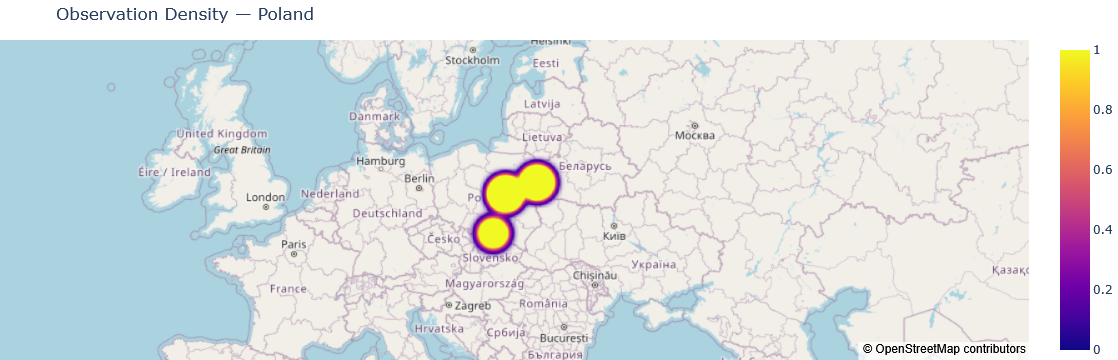

In [297]:
import plotly.express as px

# Only required if using mapbox styles
px.set_mapbox_access_token("pk_your_token_here")

fig = px.density_mapbox(
    df_country,
    lat="Latitude",
    lon="Longitude",
    z=None,                # pure point density
    radius=20,
    center=dict(
        lat=df_country["Latitude"].mean(),
        lon=df_country["Longitude"].mean()
    ),
    zoom=3,
    mapbox_style="open-street-map"
)

fig.update_layout(
    title=f"Observation Density — {country}",
    margin=dict(l=0, r=0, t=40, b=0)
)

fig.show()

In [298]:
Country = "Germany"

In [299]:
df_country1 = animals[animals["Country"] == Country]

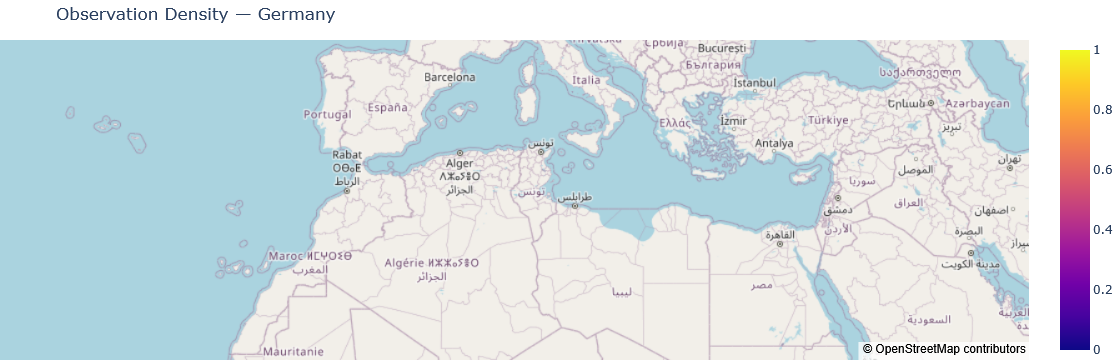

In [300]:
import plotly.express as px

# Only required if using mapbox styles
px.set_mapbox_access_token("pk_your_token_here")

fig = px.density_mapbox(
    df_country1,
    lat="Latitude",
    lon="Longitude",
    z=None,                # pure point density
    radius=20,
    center=dict(
        lat=df_country1["Latitude"].mean(),
        lon=df_country1["Longitude"].mean()
    ),
    zoom=3,
    mapbox_style="open-street-map"
)

fig.update_layout(
    title=f"Observation Density — {Country}",
    margin=dict(l=0, r=0, t=40, b=0)
)

fig.show()

**Visualize the Clusters of Data in a kmeans algorthm**

In [310]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [311]:
GermanyDataPoints = animals[(animals["Country"] == "Germany") & (animals["Latitude"] > 0) & (animals["Longitude"] > 0)]

In [312]:
GermanyDataPoints

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs,Gender_female,Gender_male,Gender_not determined
284,red squirrel,Germany,0.34,18.0,male,48.1615,11.4930,2024-03-13,Bob Bobson,0.75,False,True,False
344,hedgehog,Germany,0.80,16.0,male,52.5860,13.1471,2024-03-19,Bob Bobson,1.76,False,True,False
345,hedgehog,Germany,0.50,18.0,female,52.5862,13.1528,2024-03-19,Bob Bobson,1.10,True,False,False
346,hedgehog,Germany,0.50,18.0,male,52.5866,13.1467,2024-03-19,Bob Bobson,1.10,False,True,False
347,hedgehog,Germany,0.40,13.0,female,52.5873,13.1492,2024-03-19,Bob Bobson,0.88,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
992,hedgehog,Germany,0.60,23.0,female,49.5612,11.0822,2024-05-05,Bob Bobson,1.32,True,False,False
993,hedgehog,Germany,0.70,21.0,female,49.5595,11.1037,2024-05-05,Bob Bobson,1.54,True,False,False
994,hedgehog,Germany,0.60,23.0,male,49.5477,11.0827,2024-05-05,Bob Bobson,1.32,False,True,False
1007,hedgehog,Germany,1.00,23.0,female,49.5614,11.1053,2024-05-07,Bob Bobson,2.20,True,False,False


In [332]:
Cluster = GermanyDataPoints[["Latitude", "Longitude"]]

In [333]:
X = Cluster.iloc[:, [0,1]].values

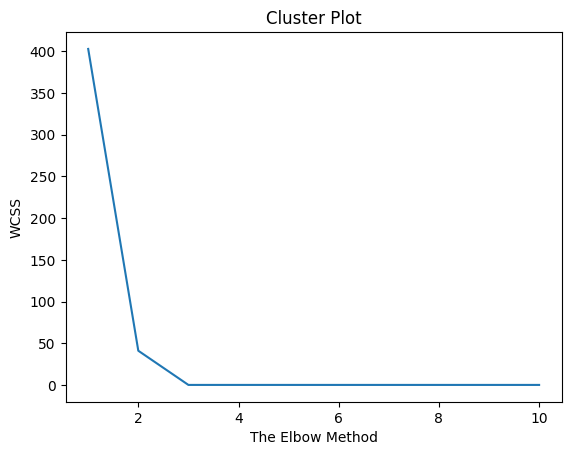

In [334]:
from sklearn.cluster import KMeans 
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init="k-means++", random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title("Cluster Plot")
plt.xlabel("The Elbow Method")
plt.ylabel("WCSS")
plt.show()

In [335]:
kmeans = KMeans(n_clusters=3, init="k-means++", random_state=42)
y_kmeans = kmeans.fit_predict(X)

In [336]:
kmeans.cluster_centers_

array([[48.16147297, 11.49305946],
       [52.58566897, 13.14926552],
       [49.55562683, 11.0875    ]])

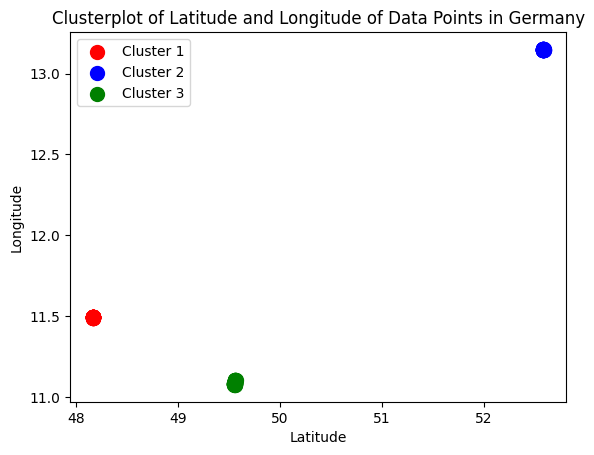

In [337]:
plt.scatter(X[y_kmeans==0,0], X[y_kmeans==0, 1], s=100, c="red", label="Cluster 1")
plt.scatter(X[y_kmeans==1,0], X[y_kmeans==1,1], s=100, c="blue", label="Cluster 2")
plt.scatter(X[y_kmeans==2,0], X[y_kmeans==2,1], s=100, c="green", label="Cluster 3")
plt.title("Clusterplot of Latitude and Longitude of Data Points in Germany")
plt.xlabel("Latitude")
plt.ylabel("Longitude")
plt.legend()
plt.show()

In [338]:
GermanyDataPoints["Cluster"] = y_kmeans

C:\Users\alexh\AppData\Local\Temp\ipykernel_21180\22895075.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [339]:
GermanyDataPoints

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs,Gender_female,Gender_male,Gender_not determined,Cluster
284,red squirrel,Germany,0.34,18.0,male,48.1615,11.4930,2024-03-13,Bob Bobson,0.75,False,True,False,0
344,hedgehog,Germany,0.80,16.0,male,52.5860,13.1471,2024-03-19,Bob Bobson,1.76,False,True,False,1
345,hedgehog,Germany,0.50,18.0,female,52.5862,13.1528,2024-03-19,Bob Bobson,1.10,True,False,False,1
346,hedgehog,Germany,0.50,18.0,male,52.5866,13.1467,2024-03-19,Bob Bobson,1.10,False,True,False,1
347,hedgehog,Germany,0.40,13.0,female,52.5873,13.1492,2024-03-19,Bob Bobson,0.88,True,False,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
992,hedgehog,Germany,0.60,23.0,female,49.5612,11.0822,2024-05-05,Bob Bobson,1.32,True,False,False,2
993,hedgehog,Germany,0.70,21.0,female,49.5595,11.1037,2024-05-05,Bob Bobson,1.54,True,False,False,2
994,hedgehog,Germany,0.60,23.0,male,49.5477,11.0827,2024-05-05,Bob Bobson,1.32,False,True,False,2
1007,hedgehog,Germany,1.00,23.0,female,49.5614,11.1053,2024-05-07,Bob Bobson,2.20,True,False,False,2


In [340]:
GermanyDataPoints["Cluster"].value_counts(normalize=3).round(3)

Cluster
2    0.383
0    0.346
1    0.271
Name: proportion, dtype: float64

In [341]:
classify = GermanyDataPoints[["Weight kg", "Body Length (CM)","Latitude", "Longitude", "Cluster"]]

In [342]:
X = classify.iloc[:, :-1].values
Y = classify.iloc[:, -1].values

In [343]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split( X, Y, test_size=0.20, random_state=42, shuffle=True)

In [344]:
from sklearn.linear_model import LogisticRegression 
lr = LogisticRegression(class_weight={0: 0.346, 1:0.271, 2:0.383})
lr.fit(X_train, Y_train)

C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



LogisticRegression(class_weight={0: 0.346, 1: 0.271, 2: 0.383})

In [345]:
y_pred = lr.predict(X_test)

In [346]:
from sklearn.metrics import confusion_matrix, balanced_accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
balanced_accuracy_score(Y_test, y_pred)

[[8 0 0]
 [0 5 0]
 [0 0 9]]


1.0

**Logistic Classification Cross Validation**

In [347]:
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegressionCV

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42, shuffle=True)

clf = LogisticRegressionCV(cv=10,
                           class_weight={0: 0.346, 1:0.271, 2:0.383},
                          scoring="accuracy",
                           random_state=0,
                           n_jobs=-1,
                          verbose=3,
                          max_iter=400).fit(X_train, Y_train)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of  10 | elapsed:   10.3s remaining:   24.1s
[Parallel(n_jobs=-1)]: Done   7 out of  10 | elapsed:   10.4s remaining:    4.4s
[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:   10.5s finished


In [348]:
y_pred = clf.predict(X_test)

In [349]:
from sklearn.metrics import confusion_matrix, balanced_accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
balanced_accuracy_score(Y_test, y_pred)

[[10  0  0]
 [ 0  7  0]
 [ 0  0 10]]


1.0

**Grid Search**

In [350]:
param_grid = [
    {
        'penalty': ['l1', 'l2', 'elasticnet', 'none'],
        'C': np.logspace(-4, 4, 20),
        'solver': ['lbfgs', 'newton-cg', 'liblinear', 'sag', 'saga'],
        'max_iter': [100, 1000, 2500, 5000],
        "class_weight": [None, 'balanced', {0: 0.366, 1: 0.503, 2: 0.131}]
    }
]

In [353]:
from sklearn.model_selection import GridSearchCV
clf1 = GridSearchCV(lr, param_grid = param_grid, verbose=True, n_jobs=-1)
clf1

GridSearchCV(estimator=LogisticRegression(class_weight={0: 0.346, 1: 0.271,
                                                        2: 0.383}),
             n_jobs=-1,
             param_grid=[{'C': array([1.00000000e-04, 2.63665090e-04, 6.95192796e-04, 1.83298071e-03,
       4.83293024e-03, 1.27427499e-02, 3.35981829e-02, 8.85866790e-02,
       2.33572147e-01, 6.15848211e-01, 1.62377674e+00, 4.28133240e+00,
       1.12883789e+01, 2.97635144e+01, 7.84759970e+01, 2.06913808e+02,
       5.45559478e+02, 1.43844989e+03, 3.79269019e+03, 1.00000000e+04]),
                          'class_weight': [None, 'balanced',
                                           {0: 0.366, 1: 0.503, 2: 0.131}],
                          'max_iter': [100, 1000, 2500, 5000],
                          'penalty': ['l1', 'l2', 'elasticnet', 'none'],
                          'solver': ['lbfgs', 'newton-cg', 'liblinear', 'sag',
                                     'saga']}],
             verbose=True)

In [358]:
best_clf_model = clf1.fit(X, Y)

Fitting 5 folds for each of 4800 candidates, totalling 24000 fits


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:547: FitFailedWarning:


15600 fits failed out of a total of 24000.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1200 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 895, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\base.py", line 1474, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1172, in fit
    s

In [355]:
print(f'Accuracy - : {best_clf_model.score(X, Y):.3f}')

Accuracy - : 1.000


In [359]:
PolandDataPoints = animals[(animals["Country"] == "Poland") & (animals["Latitude"] > 0) & (animals["Longitude"] > 0)]

In [360]:
PolandDataPoints

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs,Gender_female,Gender_male,Gender_not determined
2,European bison,Poland,930.00,335.0,male,52.8288,23.8201,2024-03-01,Anne Anthony,2050.30,False,True,False
3,European bison,Poland,909.00,311.0,not determined,52.8305,23.8268,2024-03-01,Anne Anthony,2004.00,False,False,True
4,European bison,Poland,581.00,277.0,female,52.8341,23.8071,2024-03-01,Anne Anthony,1280.88,True,False,False
5,European bison,Poland,900.00,295.0,male,52.8348,23.8172,2024-03-01,Anne Anthony,1984.16,False,True,False
6,European bison,Poland,620.00,250.0,female,52.8350,23.8208,2024-03-01,Anne Anthony,1366.86,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
991,lynx,Poland,24.00,89.0,female,52.8475,23.9061,2024-05-05,Anne Anthony,52.91,True,False,False
998,red squirrel,Poland,0.30,22.0,male,52.2128,21.0342,2024-05-06,Anne Anthony,0.66,False,True,False
999,red squirrel,Poland,0.34,22.0,male,52.2125,21.0335,2024-05-06,Anne Anthony,0.75,False,True,False
1000,red squirrel,Poland,0.31,20.0,female,52.2121,21.0335,2024-05-06,Anne Anthony,0.68,True,False,False


In [361]:
Cluster1 = PolandDataPoints[["Latitude", "Longitude"]]

In [362]:
X = Cluster1.iloc[:, [0, 1]].values

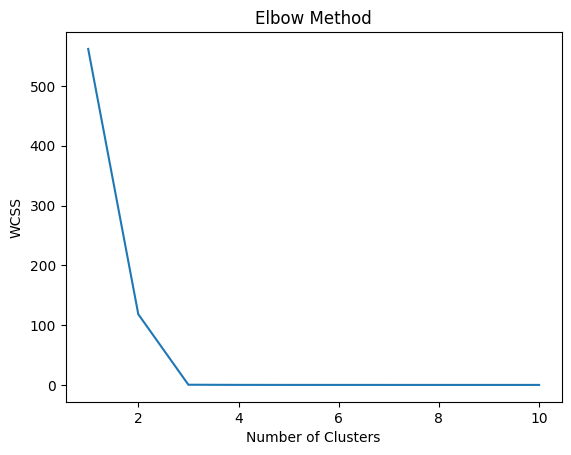

In [363]:
from sklearn.cluster import KMeans 
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init="k-means++", random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [364]:
kmeans = KMeans(n_clusters=3, init="k-means++", random_state=42)
y_kmeans = kmeans.fit_predict(X)

In [365]:
y_kmeans

array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1,
       0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 2, 2, 0, 0, 0, 1, 1, 2, 2, 2, 1, 1, 0, 0, 2,
       1, 2, 0, 2, 2, 2, 0, 2, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 0, 0, 2,
       0, 0, 2, 2, 0, 0, 0, 2, 0, 2, 2, 2, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1])

In [366]:
kmeans.cluster_centers_

array([[52.82240429, 23.79815571],
       [52.22210104, 21.0400625 ],
       [50.04148   , 19.95032   ]])

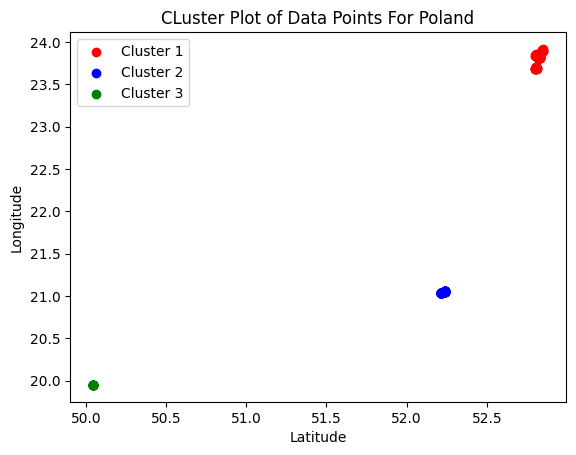

In [367]:
plt.scatter(X[y_kmeans==0,0], X[y_kmeans==0,1], color="red", label="Cluster 1")
plt.scatter(X[y_kmeans==1,0], X[y_kmeans==1,1], color="blue", label="Cluster 2")
plt.scatter(X[y_kmeans==2,0], X[y_kmeans==2,1], color="green", label="Cluster 3")
plt.title("CLuster Plot of Data Points For Poland")
plt.xlabel("Latitude")
plt.ylabel("Longitude")
plt.legend()
plt.show()

In [368]:
y_kmeans

array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1,
       0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 2, 2, 0, 0, 0, 1, 1, 2, 2, 2, 1, 1, 0, 0, 2,
       1, 2, 0, 2, 2, 2, 0, 2, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 0, 0, 2,
       0, 0, 2, 2, 0, 0, 0, 2, 0, 2, 2, 2, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1])

In [369]:
PolandDataPoints["Cluster"] = y_kmeans

C:\Users\alexh\AppData\Local\Temp\ipykernel_21180\3972678063.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [370]:
PolandDataPoints

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs,Gender_female,Gender_male,Gender_not determined,Cluster
2,European bison,Poland,930.00,335.0,male,52.8288,23.8201,2024-03-01,Anne Anthony,2050.30,False,True,False,0
3,European bison,Poland,909.00,311.0,not determined,52.8305,23.8268,2024-03-01,Anne Anthony,2004.00,False,False,True,0
4,European bison,Poland,581.00,277.0,female,52.8341,23.8071,2024-03-01,Anne Anthony,1280.88,True,False,False,0
5,European bison,Poland,900.00,295.0,male,52.8348,23.8172,2024-03-01,Anne Anthony,1984.16,False,True,False,0
6,European bison,Poland,620.00,250.0,female,52.8350,23.8208,2024-03-01,Anne Anthony,1366.86,True,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
991,lynx,Poland,24.00,89.0,female,52.8475,23.9061,2024-05-05,Anne Anthony,52.91,True,False,False,0
998,red squirrel,Poland,0.30,22.0,male,52.2128,21.0342,2024-05-06,Anne Anthony,0.66,False,True,False,1
999,red squirrel,Poland,0.34,22.0,male,52.2125,21.0335,2024-05-06,Anne Anthony,0.75,False,True,False,1
1000,red squirrel,Poland,0.31,20.0,female,52.2121,21.0335,2024-05-06,Anne Anthony,0.68,True,False,False,1


In [371]:
PolandDataPoints["Cluster"].value_counts(normalize=True).round(3)

Cluster
1    0.503
0    0.366
2    0.131
Name: proportion, dtype: float64

In [372]:
#How Accurately can I build a Classification model to predict which cluster each data point belongs to? 

In [373]:
data = PolandDataPoints[["Weight kg", "Body Length (CM)", "Latitude", "Longitude", "Cluster"]]

In [374]:
X = data.iloc[:, :-1].values

In [375]:
Y = data.iloc[:, -1].values

In [376]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42, shuffle=True)

In [378]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(class_weight={0: 0.366, 1: 0.503, 2: 0.131})
classifier.fit(X_train, Y_train)

C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



LogisticRegression(class_weight={0: 0.366, 1: 0.503, 2: 0.131})

In [379]:
y_pred = classifier.predict(X_test)

In [380]:
from sklearn.metrics import confusion_matrix, balanced_accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
balanced_accuracy_score(Y_test, y_pred)

[[14  0  0]
 [ 0 29  0]
 [ 0  5  0]]


0.6666666666666666

**Use a Logistic Regression Cross Validation**

In [382]:
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegressionCV

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42, shuffle=True)

clf = LogisticRegressionCV(cv=10,
                           class_weight={0: 0.366, 1: 0.503, 2: 0.131},
                          scoring="accuracy",
                           random_state=0,
                           n_jobs=-1,
                          verbose=3,
                          max_iter=400).fit(X_train, Y_train)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of  10 | elapsed:    0.3s remaining:    0.9s
[Parallel(n_jobs=-1)]: Done   7 out of  10 | elapsed:    0.3s remaining:    0.1s
[Parallel(n_jobs=-1)]: Done  10 out of  10 | elapsed:    0.4s finished


In [383]:
y_pred = clf.predict(X_test)

In [385]:
from sklearn.metrics import confusion_matrix, balanced_accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
balanced_accuracy_score(Y_test, y_pred)

[[14  0  0]
 [ 0 29  0]
 [ 0  0  5]]


1.0

**Use Grid Search**

In [386]:
param_grid = [
    {
        'penalty': ['l1', 'l2', 'elasticnet', 'none'],
        'C': np.logspace(-4, 4, 20),
        'solver': ['lbfgs', 'newton-cg', 'liblinear', 'sag', 'saga'],
        'max_iter': [100, 1000, 2500, 5000],
        "class_weight": [None, 'balanced', {0: 0.366, 1: 0.503, 2: 0.131}]
    }
]

In [387]:
from sklearn.model_selection import GridSearchCV
clf1 = GridSearchCV(classifier, param_grid = param_grid, verbose=True, n_jobs=-1)
clf1

GridSearchCV(estimator=LogisticRegression(class_weight={0: 0.366, 1: 0.503,
                                                        2: 0.131}),
             n_jobs=-1,
             param_grid=[{'C': array([1.00000000e-04, 2.63665090e-04, 6.95192796e-04, 1.83298071e-03,
       4.83293024e-03, 1.27427499e-02, 3.35981829e-02, 8.85866790e-02,
       2.33572147e-01, 6.15848211e-01, 1.62377674e+00, 4.28133240e+00,
       1.12883789e+01, 2.97635144e+01, 7.84759970e+01, 2.06913808e+02,
       5.45559478e+02, 1.43844989e+03, 3.79269019e+03, 1.00000000e+04]),
                          'class_weight': [None, 'balanced',
                                           {0: 0.366, 1: 0.503, 2: 0.131}],
                          'max_iter': [100, 1000, 2500, 5000],
                          'penalty': ['l1', 'l2', 'elasticnet', 'none'],
                          'solver': ['lbfgs', 'newton-cg', 'liblinear', 'sag',
                                     'saga']}],
             verbose=True)

In [388]:
best_clf_model = clf1.fit(X, Y)

Fitting 5 folds for each of 4800 candidates, totalling 24000 fits


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:547: FitFailedWarning:


15600 fits failed out of a total of 24000.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1200 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 895, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\base.py", line 1474, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1172, in fit
    s

In [389]:
print(f'Accuracy - : {best_clf_model.score(X, Y):.3f}')

Accuracy - : 1.000


In [390]:
DataPoints = animals[(animals["Latitude"] > 0) & (animals["Longitude"] > 0)]

In [391]:
DataPoints

,Animal type,Country,Weight kg,Body Length (CM),Gender,Latitude,Longitude,Observation Date,Data Complied By,Weight lbs,Gender_female,Gender_male,Gender_not determined
2,European bison,Poland,930.00,335.0,male,52.8288,23.8201,2024-03-01,Anne Anthony,2050.30,False,True,False
3,European bison,Poland,909.00,311.0,not determined,52.8305,23.8268,2024-03-01,Anne Anthony,2004.00,False,False,True
4,European bison,Poland,581.00,277.0,female,52.8341,23.8071,2024-03-01,Anne Anthony,1280.88,True,False,False
5,European bison,Poland,900.00,295.0,male,52.8348,23.8172,2024-03-01,Anne Anthony,1984.16,False,True,False
6,European bison,Poland,620.00,250.0,female,52.8350,23.8208,2024-03-01,Anne Anthony,1366.86,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1005,hedgehog,Hungary,0.90,23.0,male,47.5101,18.9444,2024-05-07,Anne Anthony,1.98,False,True,False
1006,red squirrel,Poland,0.35,20.0,female,52.2120,21.0332,2024-05-07,Anne Anthony,0.77,True,False,False
1007,hedgehog,Germany,1.00,23.0,female,49.5614,11.1053,2024-05-07,Bob Bobson,2.20,True,False,False
1008,hedgehog,Germany,0.50,17.0,female,49.5616,11.0870,2024-05-07,Bob Bobson,1.10,True,False,False


In [395]:
DataPoints["Gender_male"].value_counts()

Gender_male
False    389
True     359
Name: count, dtype: int64

**Build a Random Forest Classification Model to predict whether animal is a male**

In [396]:
numbers = DataPoints[["Weight kg", "Body Length (CM)", "Latitude", "Longitude", "Gender_male"]]

In [397]:
X = numbers.iloc[:, :-1].values 
Y = numbers.iloc[:, -1].values 

In [398]:
X

array([[9.30000e+02, 3.35000e+02, 5.28288e+01, 2.38201e+01],
       [9.09000e+02, 3.11000e+02, 5.28305e+01, 2.38268e+01],
       [5.81000e+02, 2.77000e+02, 5.28341e+01, 2.38071e+01],
       ...,
       [1.00000e+00, 2.30000e+01, 4.95614e+01, 1.11053e+01],
       [5.00000e-01, 1.70000e+01, 4.95616e+01, 1.10870e+01],
       [9.00000e-01, 1.60000e+01, 4.75099e+01, 1.89399e+01]])

In [399]:
Y

array([ True, False, False,  True, False,  True, False, False, False,
        True, False, False,  True, False,  True,  True,  True,  True,
        True, False,  True, False, False,  True, False, False,  True,
        True, False,  True,  True,  True,  True, False,  True, False,
        True, False, False, False, False,  True,  True, False, False,
       False,  True, False,  True,  True,  True, False,  True, False,
       False,  True,  True,  True, False,  True, False,  True,  True,
       False,  True, False, False,  True,  True, False, False, False,
        True,  True, False, False, False,  True, False,  True,  True,
       False, False, False,  True,  True, False,  True,  True, False,
        True, False, False,  True, False,  True, False, False, False,
        True,  True,  True, False,  True, False,  True, False, False,
        True,  True, False,  True, False,  True, False,  True,  True,
       False, False, False, False,  True, False, False, False, False,
        True,  True,

In [400]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, shuffle=True, random_state=42) 

In [401]:
from sklearn.ensemble import RandomForestClassifier
classifier = RandomForestClassifier(n_estimators=15, criterion="entropy", random_state=42)
classifier.fit(X_train, Y_train)

RandomForestClassifier(criterion='entropy', n_estimators=15, random_state=42)

In [402]:
y_pred = classifier.predict(X_test)

In [403]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[63 33]
 [48 43]]


0.5668449197860963

**Visualize Feature Importances of Bar Graph**

In [428]:
classifier.feature_importances_

array([0.20354881, 0.21359403, 0.28788781, 0.29496935])

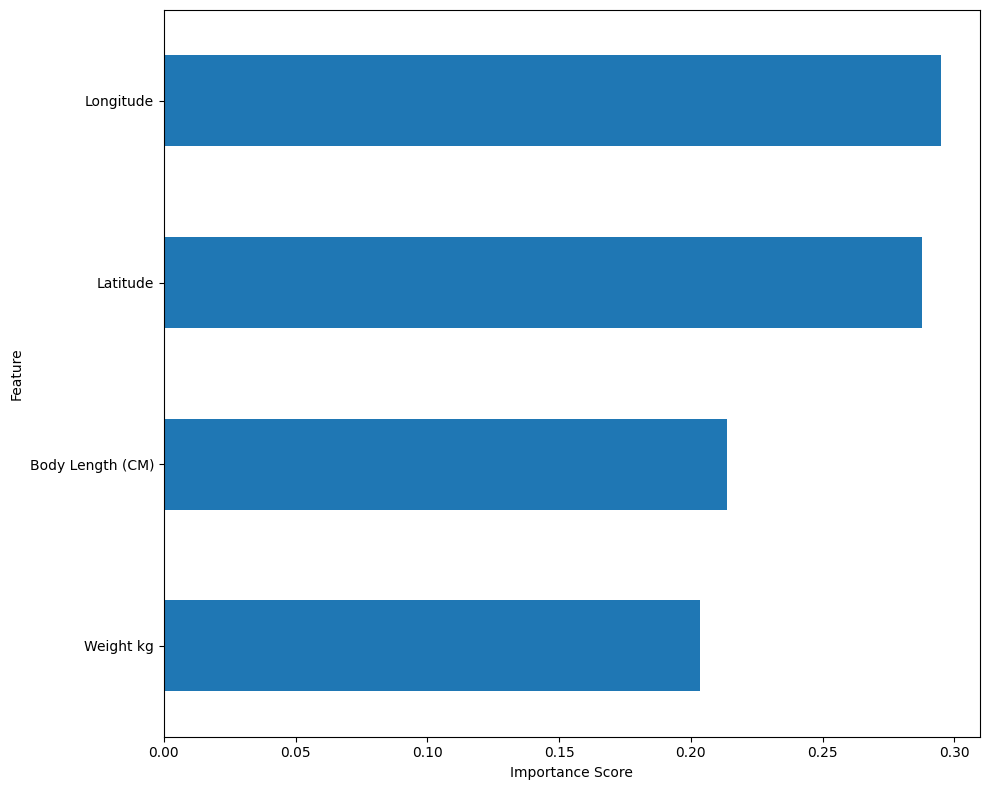

In [439]:
feature_names = numbers.columns[:-1]

feature_importances = pd.Series(
    classifier.feature_importances_,
    index=feature_names
)

feature_importances = feature_importances.sort_values(ascending=True)

ax = feature_importances.plot(
    kind='barh',
    figsize=(10, 8)
)

ax.set_xlabel("Importance Score")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

In [411]:
param_grid = {
    'n_estimators': [100, 230],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 4, 6],
    'min_samples_leaf': [1, 2, 3],
    'bootstrap': [True, False]
}

In [412]:
grid_search = GridSearchCV(RandomForestClassifier(), param_grid=param_grid, cv=5)

In [413]:
grid_search.fit(X_train, Y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(),
             param_grid={'bootstrap': [True, False],
                         'max_depth': [None, 5, 10, 15],
                         'min_samples_leaf': [1, 2, 3],
                         'min_samples_split': [2, 4, 6],
                         'n_estimators': [100, 230]})

In [414]:
y_pred = grid_search.predict(X_test)

In [415]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[60 36]
 [49 42]]


0.5454545454545454

In [416]:
from sklearn.model_selection import RandomizedSearchCV
param_distributions = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 4, 6]
}

random_search = RandomizedSearchCV(RandomForestClassifier(), param_distributions, n_iter=50, cv=5, n_jobs=-1)

In [418]:
random_search.fit(X_train, Y_train)

C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:318: UserWarning:

The total space of parameters 27 is smaller than n_iter=50. Running 27 iterations. For exhaustive searches, use GridSearchCV.



RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(), n_iter=50,
                   n_jobs=-1,
                   param_distributions={'max_depth': [10, 20, None],
                                        'min_samples_split': [2, 4, 6],
                                        'n_estimators': [100, 200, 300]})

In [419]:
y_pred = random_search.predict(X_test)

In [420]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[60 36]
 [47 44]]


0.5561497326203209

**Drop Weight and Body Length**

In [458]:
numbers1 = animals[["Latitude", "Longitude", "Gender_male"]]

In [467]:
X = numbers1[["Latitude", "Longitude"]]
Y = numbers1["Gender_male"] 

In [468]:
X

,Latitude,Longitude
0,0.0000,0.0000
1,0.0000,0.0000
2,52.8288,23.8201
3,52.8305,23.8268
4,52.8341,23.8071
...,...,...
1005,47.5101,18.9444
1006,52.2120,21.0332
1007,49.5614,11.1053
1008,49.5616,11.0870


In [469]:
Y

0       False
1       False
2        True
3       False
4       False
        ...  
1005     True
1006    False
1007    False
1008    False
1010    False
Name: Gender_male, Length: 825, dtype: bool

In [470]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42, shuffle=True)

In [472]:
from sklearn.ensemble import RandomForestClassifier
classifier = RandomForestClassifier(criterion='entropy', n_estimators=20, random_state=42)
classifier.fit(X_train, Y_train)

RandomForestClassifier(criterion='entropy', n_estimators=20, random_state=42)

In [473]:
y_pred = classifier.predict(X_test)

In [474]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[47 49]
 [59 52]]


0.4782608695652174

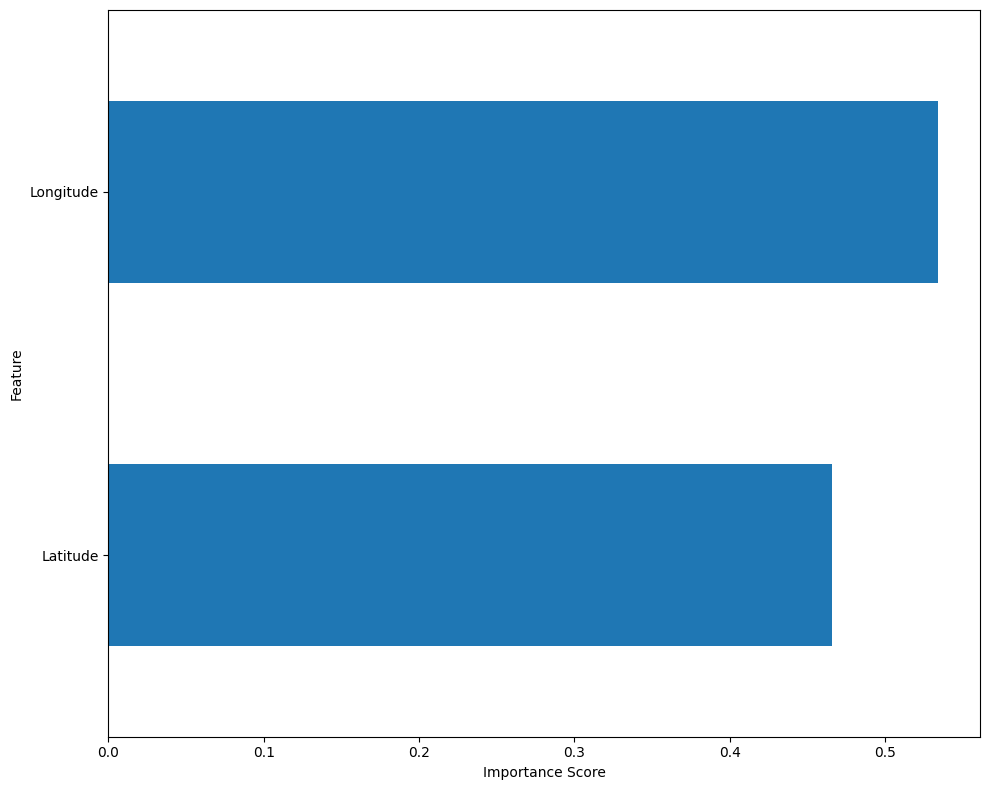

In [475]:
feature_names = numbers1.columns[:-1]

feature_importances = pd.Series(
    classifier.feature_importances_,
    index=feature_names
)

feature_importances = feature_importances.sort_values(ascending=True)

ax = feature_importances.plot(
    kind='barh',
    figsize=(10, 8)
)

ax.set_xlabel("Importance Score")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

In [476]:
DataPoints["Gender_female"].value_counts()

Gender_female
True     380
False    368
Name: count, dtype: int64

In [492]:
numbers2 = DataPoints[["Weight kg", "Body Length (CM)", "Latitude", "Longitude", "Gender_female"]]

In [493]:
X = numbers2.iloc[:, :-1].values
Y = numbers2.iloc[:, -1].values

In [494]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42, shuffle=True)

In [495]:
from sklearn.ensemble import RandomForestClassifier
classifier = RandomForestClassifier(criterion='entropy', random_state=42, n_estimators=20)
classifier.fit(X_train, Y_train)

RandomForestClassifier(criterion='entropy', n_estimators=20, random_state=42)

In [496]:
y_pred = classifier.predict(X_test)

In [497]:
from sklearn.metrics import accuracy_score, confusion_matrix
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[54 40]
 [43 50]]


0.5561497326203209

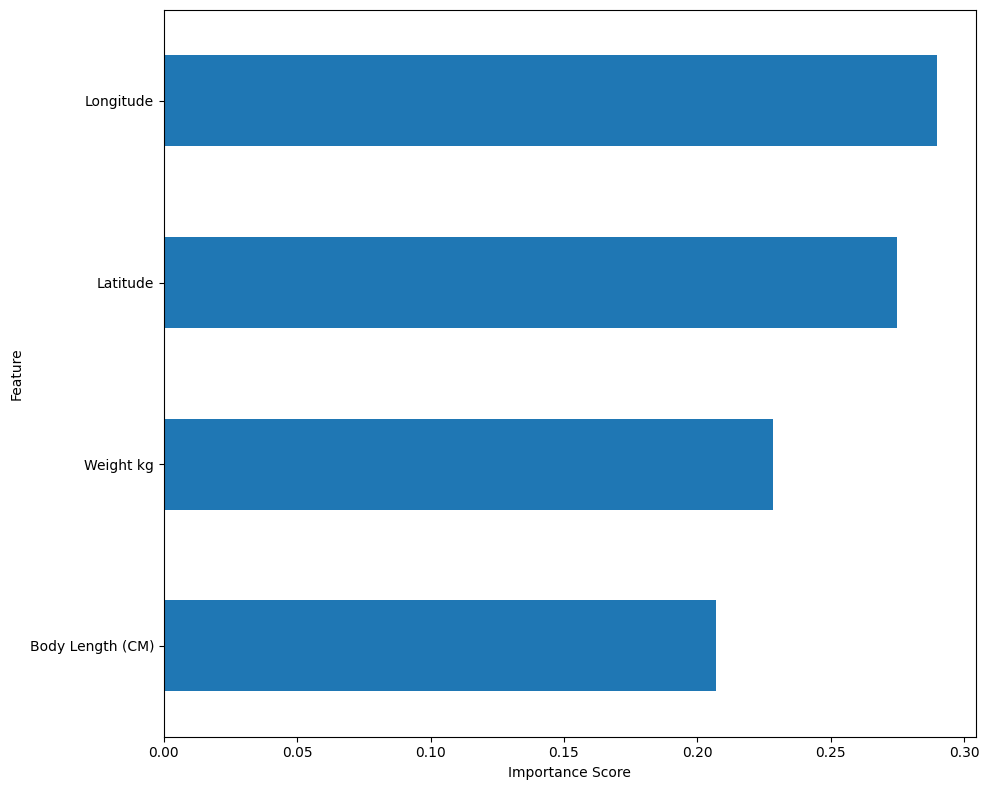

In [498]:
feature_names = numbers2.columns[:-1]

feature_importances = pd.Series(
    classifier.feature_importances_,
    index=feature_names
)

feature_importances = feature_importances.sort_values(ascending=True)

ax = feature_importances.plot(
    kind='barh',
    figsize=(10, 8)
)

ax.set_xlabel("Importance Score")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

In [499]:
numbers3 = DataPoints[["Latitude", "Longitude", "Gender_female"]]

In [500]:
X = numbers3.iloc[:, :-1].values
Y = numbers3.iloc[:, -1].values

In [501]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42, shuffle=True)

In [502]:
from sklearn.ensemble import RandomForestClassifier
classifier = RandomForestClassifier(criterion='entropy', random_state=42, n_estimators=20)
classifier.fit(X_train, Y_train)

RandomForestClassifier(criterion='entropy', n_estimators=20, random_state=42)

In [503]:
y_pred = classifier.predict(X_test)

In [504]:
from sklearn.metrics import accuracy_score, confusion_matrix
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[50 44]
 [49 44]]


0.5026737967914439

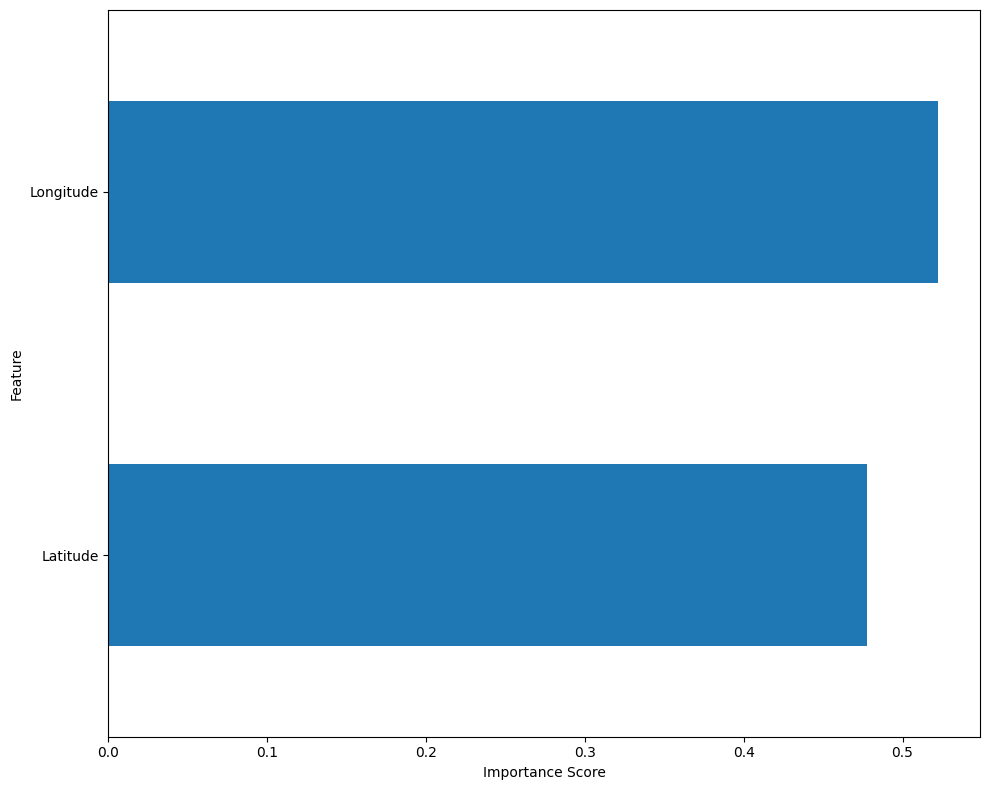

In [505]:
feature_names = numbers3.columns[:-1]

feature_importances = pd.Series(
    classifier.feature_importances_,
    index=feature_names
)

feature_importances = feature_importances.sort_values(ascending=True)

ax = feature_importances.plot(
    kind='barh',
    figsize=(10, 8)
)

ax.set_xlabel("Importance Score")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()